In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple
from pathlib import Path
import os
from glob import glob

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys
import h5py
from scipy import signal
# Add src to path for custom utilities
sys.path.insert(0, f'/home/obandohe/JIPSENSE/JIPSENSE')
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info
from src.utils.fk_spectrum_class import FKSpectrum
from src.utils.Preprocessing_SW import agc_gain, Array_to_ObsPy
import src.utils.wft as wft
from obspy.signal.tf_misfit import cwt
print("✓ All libraries imported successfully")
from obspy import Trace, Stream, UTCDateTime

✓ All libraries imported successfully


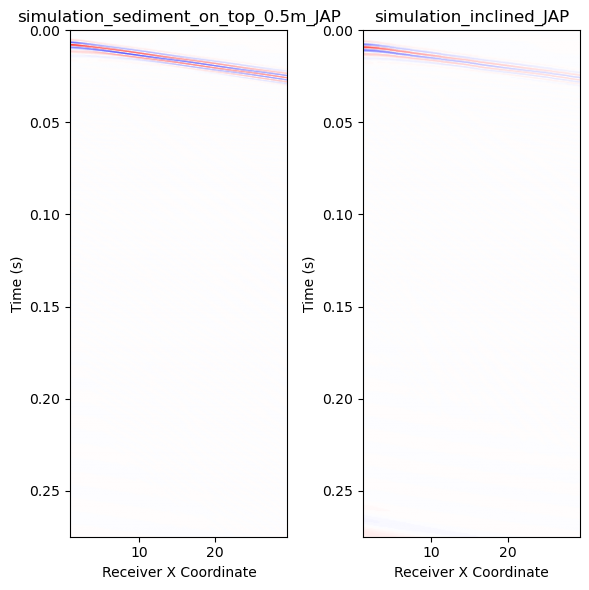

In [8]:
# read STATIONS

models = ['simulation_sediment_on_top_0.5m_JAP', 'simulation_inclined_JAP']

#models = ['simulation_no_sediment_on_top', 'simulation_coupling_no_sediment_on_top', 'simulation_coupling_sediment_on_top']


#models = ['simulation_no_sediment_on_top','simulation_sediment_on_top_0.5m','simulation_sediment_on_top_0.75m', 'simulation_sediment_on_top_1.0m','simulation_sediment_on_top_1.5m']

fig,axs = plt.subplots(1, len(models), figsize=(6, 6))


for ii, model_name in enumerate(models):

    signal_type = 'PRE.semp'

    if signal_type=='PRE.semp':
        signal_suffix = 'pressure'
    elif signal_type=='FXX.semv':
        signal_suffix = 'VXX'
    elif signal_type=='FXZ.semv':
        signal_suffix = 'VXZ'
    else:
        raise ValueError(f"Unsupported signal type: {signal_type}")

    source_type = 'tr'  # or 'tr'

    # test saving and loading the h5 file
    filename = f"/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/hdf5_files_JAP/{model_name}_{signal_suffix}_{source_type}.h5"
    with h5py.File(filename, "r") as f:
        data_loaded = f["data"][:]
        fs_loaded = f["fs"][()]
        station_coords_loaded = f["receiver_coordinates"][:]
        params_loaded = f["params"][()].decode("utf-8")


    data_loaded = data_loaded[:550,:]

    # convert the loaded data to obspy obspy Trace objects


    traces = []
    for i in range(data_loaded.shape[1]):
        tr = Trace()
        tr.data = data_loaded[:, i]
        tr.stats.station = f"STA{i:03d}"
        tr.stats.network = "XX"
        tr.stats.channel = signal_suffix
        tr.stats.sampling_rate = fs_loaded
        tr.stats.starttime = UTCDateTime(0)
        traces.append(tr)

    st = Stream(traces=traces)

    # filter the stream with a bandpass filter
    st.filter("bandpass", freqmin=50.0, freqmax=600.0)

    # extract data from the obspy Stream object
    data_from_stream = np.array([tr.data for tr in st]).T



    axs[ii].imshow(data_from_stream, aspect='auto', cmap='seismic',vmin=-0.15, vmax=0.15, extent=[station_coords_loaded[:, 0].min(), station_coords_loaded[:, 0].max(), data_from_stream.shape[0]/fs_loaded, 0])
    #plt.colorbar(ax=axs[ii], label=signal_suffix)
    axs[ii].set_xlabel('Receiver X Coordinate')
    axs[ii].set_ylabel('Time (s)')

    if ii==0:
        name_ = '0.0m'
    else:
        name_ = model_name.split('_')[-1]


    axs[ii].set_title(model_name)

plt.tight_layout()
plt.show()

